# Histogram Equalization pada Citra Digital

Praktikum operasi dasar citra digital menggunakan metode **Histogram Equalization**, yaitu pemerataan distribusi intensitas piksel untuk meningkatkan kontras citra.

## 1. Import Library
OpenCV, NumPy, Matplotlib, dan OS digunakan untuk membaca, mengolah, menampilkan, serta memperoleh informasi gambar.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

## 2. Membaca Gambar
Gambar dibaca dengan OpenCV (format BGR), lalu dikonversi ke RGB agar warna benar saat ditampilkan Matplotlib.

In [2]:
nama_file = "foto asli.jpg"
img_bgr = cv2.imread(nama_file)
if img_bgr is None:
    raise FileNotFoundError(f"File '{nama_file}' tidak ditemukan.")
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
print("Gambar berhasil dibaca.")

Gambar berhasil dibaca.


## 3. Menampilkan Gambar Asli
Gambar asli ditampilkan sebagai acuan sebelum dilakukan equalization.

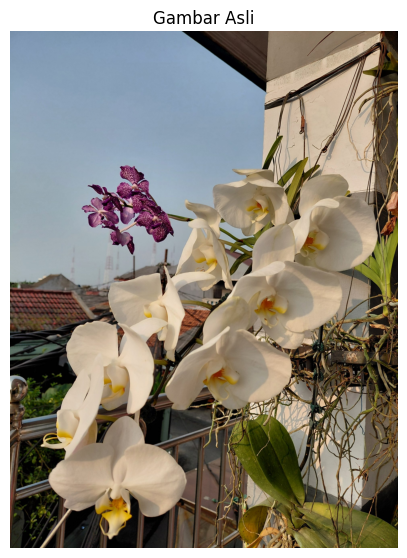

In [3]:
plt.figure(figsize=(5, 7))
plt.imshow(img_rgb)
plt.title("Gambar Asli")
plt.axis("off")
plt.show()

## 4. Informasi Gambar Asli
Karakteristik gambar dianalisis melalui dimensi, jumlah piksel, ukuran file, tipe data, serta statistik intensitas piksel.

In [4]:
tinggi, lebar, kanal = img_rgb.shape
print("Dimensi gambar   :", img_rgb.shape, "(tinggi x lebar x kanal)")
print("Jumlah piksel    :", tinggi * lebar)
print("Ukuran file      : %.2f KB" % (os.path.getsize(nama_file) / 1024))
print("Tipe data        :", img_rgb.dtype)
print("Intensitas min   :", img_rgb.min())
print("Intensitas max   :", img_rgb.max())
print("Intensitas mean  : %.2f" % img_rgb.mean())
print("Intensitas std   : %.2f" % img_rgb.std())

Dimensi gambar   : (2576, 1932, 3) (tinggi x lebar x kanal)
Jumlah piksel    : 4976832
Ukuran file      : 737.12 KB
Tipe data        : uint8
Intensitas min   : 0
Intensitas max   : 255
Intensitas mean  : 121.23
Intensitas std   : 62.57


## 5. Konversi ke Grayscale
Histogram equalization diterapkan pada kanal intensitas tunggal, sehingga gambar dikonversi ke grayscale terlebih dahulu.

In [5]:
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
print("Dimensi grayscale:", gray.shape)

Dimensi grayscale: (2576, 1932)


## 6. Histogram, CDF, dan Transformasi Intensitas
Langkah manual:

1. Histogram `h(k)` = jumlah piksel dengan intensitas `k`.
2. CDF = jumlah kumulatif histogram.
3. Transformasi: `s_k = round((CDF(k) - CDF_min) / (N - CDF_min) x 255)`.
4. Setiap piksel dipetakan ke nilai barunya melalui look-up table (LUT).

Hasil manual kemudian diverifikasi dengan fungsi bawaan `cv2.equalizeHist`.

In [6]:
hist = np.bincount(gray.ravel(), minlength=256)
cdf = hist.cumsum()
cdf_min = cdf[cdf > 0].min()
N = gray.size

lut = np.round((cdf - cdf_min) / (N - cdf_min) * 255).clip(0, 255).astype(np.uint8)
gray_eq = lut[gray]

# Verifikasi dengan OpenCV
gray_cv = cv2.equalizeHist(gray)
print("Selisih maksimum dengan cv2.equalizeHist:", np.abs(gray_eq.astype(int) - gray_cv.astype(int)).max())

Selisih maksimum dengan cv2.equalizeHist: 0


## 7. Perbandingan Gambar
Gambar asli (grayscale) dan hasil equalization ditampilkan berdampingan beserta histogramnya untuk melihat perubahan secara visual.

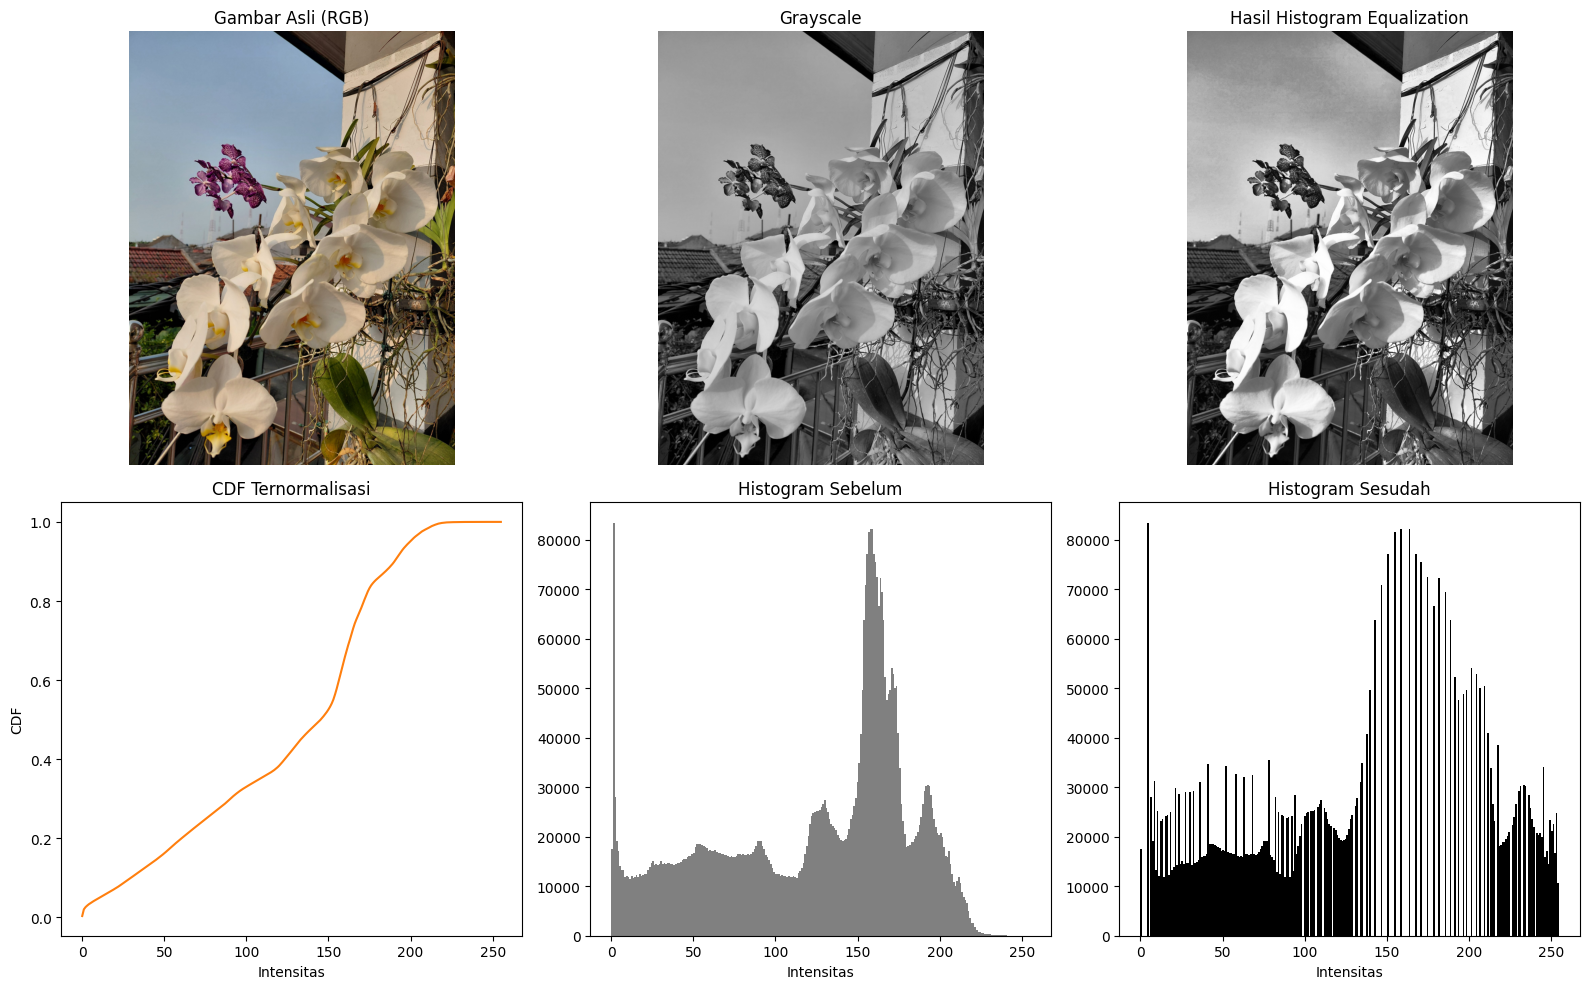

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(16, 10))

ax[0, 0].imshow(img_rgb);                              ax[0, 0].set_title("Gambar Asli (RGB)")
ax[0, 1].imshow(gray, cmap="gray", vmin=0, vmax=255);  ax[0, 1].set_title("Grayscale")
ax[0, 2].imshow(gray_eq, cmap="gray", vmin=0, vmax=255); ax[0, 2].set_title("Hasil Histogram Equalization")
for a in ax[0]:
    a.axis("off")

ax[1, 0].plot(cdf / N, color="tab:orange")
ax[1, 0].set_title("CDF Ternormalisasi"); ax[1, 0].set_xlabel("Intensitas"); ax[1, 0].set_ylabel("CDF")

ax[1, 1].hist(gray.ravel(), bins=256, range=(0, 255), color="gray")
ax[1, 1].set_title("Histogram Sebelum"); ax[1, 1].set_xlabel("Intensitas")

ax[1, 2].hist(gray_eq.ravel(), bins=256, range=(0, 255), color="black")
ax[1, 2].set_title("Histogram Sesudah"); ax[1, 2].set_xlabel("Intensitas")

plt.tight_layout()
plt.show()

## 8. Menyimpan Hasil
Gambar grayscale dan hasil equalization disimpan sebagai file terpisah di folder `hasil`.

In [8]:
os.makedirs("hasil", exist_ok=True)
cv2.imwrite("hasil/grayscale.png", gray)
cv2.imwrite("hasil/equalized.png", gray_eq)
print("File tersimpan di folder 'hasil':", os.listdir("hasil"))

File tersimpan di folder 'hasil': ['equalized.png', 'grayscale.png']


## 9. Analisis Intensitas Piksel
Rata-rata dan standar deviasi intensitas dibandingkan sebelum dan sesudah equalization. Standar deviasi yang lebih besar menandakan kontras yang meningkat.

In [9]:
print("Rata-rata intensitas  : asli = %.2f | equalized = %.2f" % (gray.mean(), gray_eq.mean()))
print("Std. deviasi (kontras): asli = %.2f | equalized = %.2f" % (gray.std(), gray_eq.std()))
print("Rentang intensitas    : asli = %d-%d | equalized = %d-%d" % (gray.min(), gray.max(), gray_eq.min(), gray_eq.max()))

Rata-rata intensitas  : asli = 123.88 | equalized = 127.90
Std. deviasi (kontras): asli = 59.04 | equalized = 74.05
Rentang intensitas    : asli = 0-250 | equalized = 0-255


## Kesimpulan

Berdasarkan praktikum yang telah dilakukan, metode *Histogram Equalization* berhasil diterapkan untuk meningkatkan kontras citra digital.

1. **Import Library:** OpenCV, NumPy, Matplotlib, dan OS digunakan untuk membaca, mengolah, menampilkan, serta memperoleh informasi gambar.
2. **Membaca Gambar:** Gambar asli berhasil dibaca menggunakan OpenCV sebagai input pengolahan citra.
3. **Menampilkan Gambar Asli:** Gambar ditampilkan sebagai acuan sebelum dilakukan equalization.
4. **Informasi Gambar Asli:** Karakteristik gambar dianalisis melalui dimensi (1932 x 2576 piksel), jumlah piksel, ukuran file, tipe data, serta statistik intensitas piksel.
5. **Konversi Grayscale:** Gambar dikonversi ke skala keabuan agar equalization dapat diterapkan pada satu kanal intensitas.
6. **Histogram Equalization:** Histogram dan CDF dihitung manual, lalu dipakai sebagai tabel transformasi intensitas. Hasilnya identik dengan fungsi `cv2.equalizeHist`.
7. **Perbandingan Gambar:** Gambar asli dan hasil equalization ditampilkan berdampingan beserta histogramnya untuk melihat perubahan secara visual.
8. **Menyimpan Hasil:** Gambar grayscale dan hasil equalization disimpan sebagai file terpisah di folder `hasil`.
9. **Analisis Intensitas Piksel:** Standar deviasi intensitas (ukuran kontras) meningkat dari 59,04 pada gambar asli menjadi 74,05 setelah equalization, sedangkan rata-rata intensitas berubah dari 123,88 menjadi 127,90.

Dengan demikian, hasil visual dan numerik menunjukkan bahwa Histogram Equalization dapat meratakan sebaran intensitas piksel sehingga detail pada area yang terlalu terang maupun terlalu gelap menjadi lebih jelas.